In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\immek\Telco Customer Churn.csv.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
df.info()

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-

In [3]:
# Remove extra spaces
df["TotalCharges"] = df["TotalCharges"].str.strip()

# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
print(df["TotalCharges"].dtype)

Missing TotalCharges: 11
float64


In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing Values After Cleaning:")
print(df["TotalCharges"].isnull().sum())

print("\nData Type:")
print(df["TotalCharges"].dtype)

Missing Values After Cleaning:
0

Data Type:
float64


In [5]:
# Total customers
total_customers = len(df)

# Churned customers
churned_customers = (df["Churn"] == "Yes").sum()

# Retained customers
retained_customers = (df["Churn"] == "No").sum()

# Churn rate
churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Overall Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Overall Churn Rate: 26.54 %


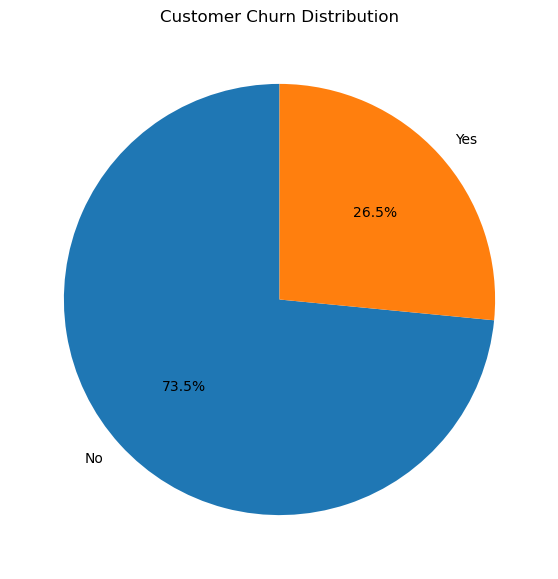

In [6]:
churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Distribution")
plt.show()

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


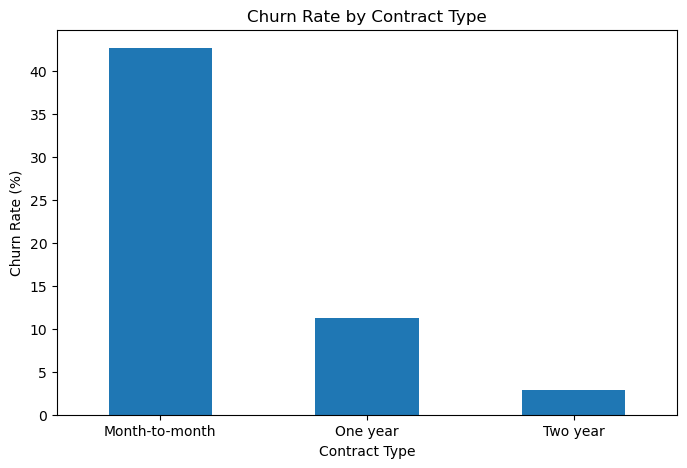

In [7]:
# Calculate churn rate by contract type
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Contract Type:")
print(contract_churn.round(2))

# Create bar chart
plt.figure(figsize=(8, 5))

contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

Churn Rate by Tenure:
TenureGroup
0-12 Months     47.68
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Churn, dtype: float64


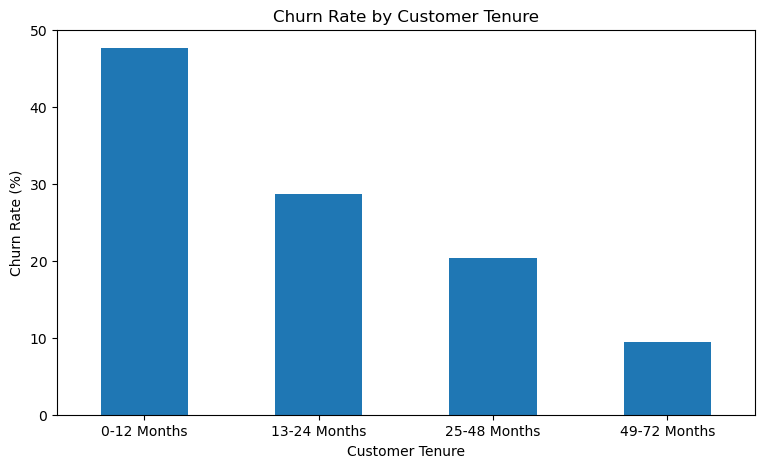

In [8]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49-72 Months"]
)

# Calculate churn rate
tenure_churn = df.groupby(
    "TenureGroup", observed=False
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Tenure:")
print(tenure_churn.round(2))

# Visualization
plt.figure(figsize=(9, 5))
tenure_churn.plot(kind="bar")
plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

Churn Rate by Internet Service:
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


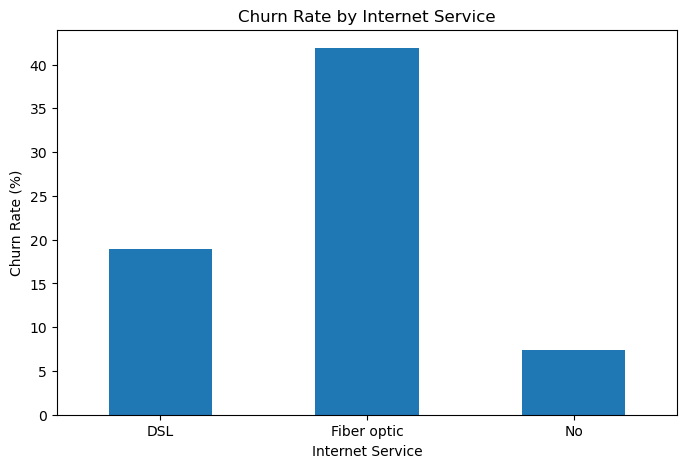

In [9]:
# Churn rate by Internet Service
internet_churn = df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Internet Service:")
print(internet_churn.round(2))

# Visualization
plt.figure(figsize=(8, 5))
internet_churn.plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

Churn Rate by Payment Method:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


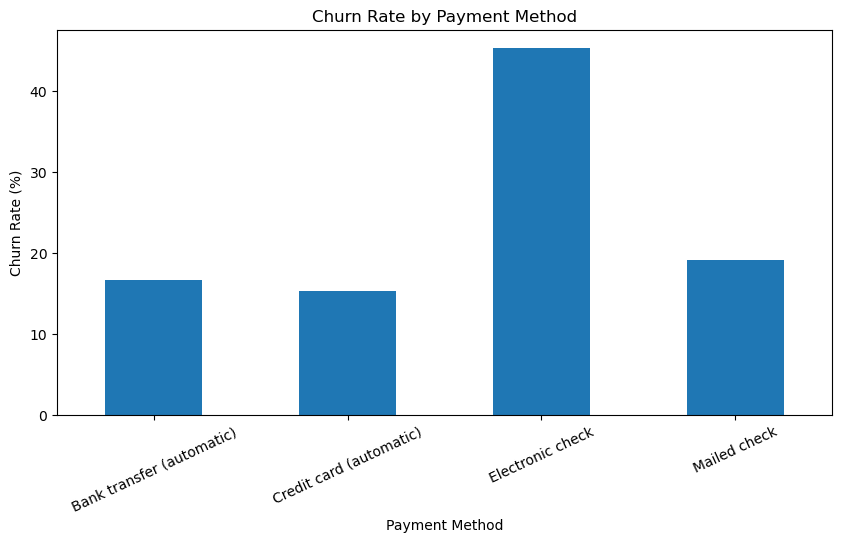

In [10]:
payment_churn = df.groupby("PaymentMethod")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Payment Method:")
print(payment_churn.round(2))

# Visualization
plt.figure(figsize=(10, 5))

payment_churn.plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)
plt.show()

In [11]:
features = ["OnlineSecurity", "TechSupport"]

for feature in features:
    result = df.groupby(feature)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    print("\nChurn Rate by", feature)
    print(result.round(2))


Churn Rate by OnlineSecurity
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

Churn Rate by TechSupport
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64


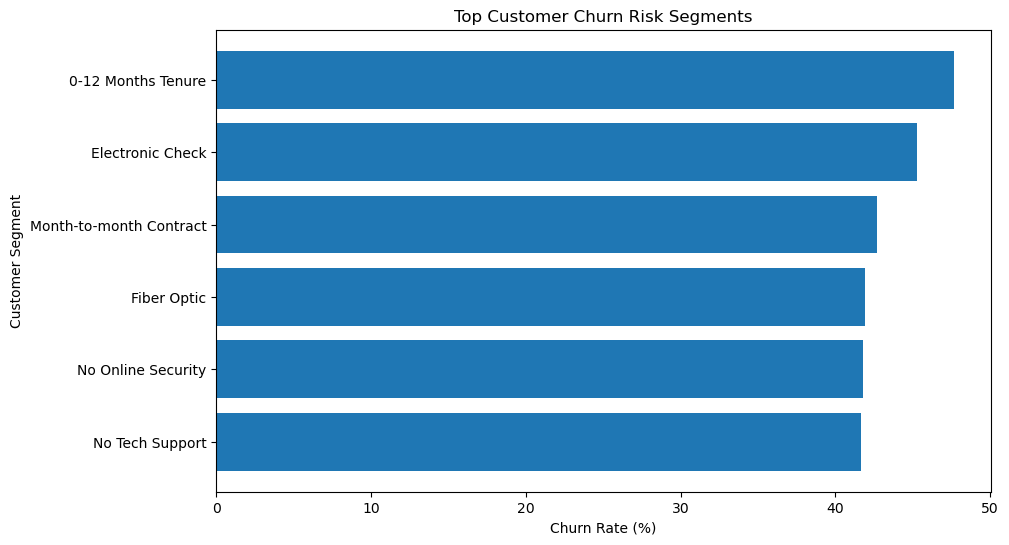

          Customer Segment  Churn Rate
0       0-12 Months Tenure       47.68
1         Electronic Check       45.29
2  Month-to-month Contract       42.71
3              Fiber Optic       41.89
4       No Online Security       41.77
5          No Tech Support       41.64


In [12]:
driver_data = {
    "Customer Segment": [
        "0-12 Months Tenure",
        "Electronic Check",
        "Month-to-month Contract",
        "Fiber Optic",
        "No Online Security",
        "No Tech Support"
    ],
    "Churn Rate": [
        47.68, 45.29, 42.71, 41.89, 41.77, 41.64
    ]
}

driver_df = pd.DataFrame(driver_data)

driver_df = driver_df.sort_values(
    by="Churn Rate", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    driver_df["Customer Segment"],
    driver_df["Churn Rate"]
)

plt.title("Top Customer Churn Risk Segments")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Segment")
plt.show()

print(driver_df.sort_values(
    by="Churn Rate", ascending=False
))

In [13]:
df.to_csv("Cleaned_Telco_Churn.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
